# Домашнее задание по теме «Деревья решений: регрессия и классификация»

В работе две части: регрессия на Wine Quality и классификация на Adult. Ты сравнишь настройки sklearn и допишешь учебные реализации деревьев.

**Максимальная оценка: 10 баллов.** Задачи 1–5 дают 1, 2, 2, 2 и 2 балла, теоретические вопросы ещё 1 балл. Баллы подзадач входят в баллы задания и не прибавляются к ним повторно.

## Часть I. Деревья регрессии

Импортируем библиотеки и [загрузим датасет Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality).

Датасет Wine Quality содержит данные о португальских винах Vinho Verde. В датасете два отдельных файла: около 1 600 записей для красного вина и почти 4 900 для белого. На каждый образец приходится 11 физических и химических характеристик (фиксированная кислотность, летучая кислотность, цитрат, остаточный сахар, хлориды, свободный и общий диоксид серы, плотность, pH, сульфаты и содержание алкоголя) и целевая метка `quality` — оценка дегустатора от 0 до 10 (на практике в диапазоне ~ 3–9).

Обычно Wine Quality используют для задач регрессии, чтобы предсказать точечную оценку. Или для бинарной классификации, например, чтобы определить «низкое» или «высокое» качество, где порог — это 6. Используем датасет для задачи регрессии и  предскажем переменную `quality`.



In [1]:
# Импорт библиотек
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import seaborn as sns

Теперь загрузим датасет и проведём разведочный анализ данных (EDA) и препроцессинг.

In [2]:
# 1. Ссылки на CSV
red_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
white_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

# 2. Считываем в DataFrame, указывая разделитель ';'
df_red = pd.read_csv(red_url, sep=';')
df_white = pd.read_csv(white_url, sep=';')

# 3. Добавляем колонку с типом вина
df_red["type"] = "red"
df_white["type"] = "white"

# 4. Объединяем
df = pd.concat([df_red, df_white], ignore_index=True)

# Удаляем точные повторы до разбиения, чтобы они не попадали в разные части.
df = df.drop_duplicates().reset_index(drop=True)
df_dev, df_holdout = train_test_split(df, test_size=0.2, random_state=0)
df, df_val = train_test_split(df_dev, test_size=0.25, random_state=0)
df, df_val, df_holdout = df.copy(), df_val.copy(), df_holdout.copy()

# EDA проводим по train.
# 5. Проверка
print(df.shape)   # Сколько записей и признаков
df.head()

(3192, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
4636,6.9,0.380,0.28,8.30,0.062,22.0,166.0,0.99506,3.16,0.72,10.6,5,white
1685,6.3,0.390,0.35,5.90,0.040,82.5,260.0,0.99410,3.12,0.66,10.1,5,white
2373,6.8,0.180,0.37,1.50,0.027,37.0,93.0,0.99200,3.30,0.45,10.8,6,white
5311,4.9,0.235,0.27,11.75,0.030,34.0,118.0,0.99540,3.07,0.50,9.4,6,white
951,5.6,0.660,0.00,2.50,0.066,7.0,15.0,0.99256,3.52,0.58,12.9,5,red


In [3]:
# Нет пропусков, один категориальный признак
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3192 entries, 4636 to 4846
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         3192 non-null   float64
 1   volatile acidity      3192 non-null   float64
 2   citric acid           3192 non-null   float64
 3   residual sugar        3192 non-null   float64
 4   chlorides             3192 non-null   float64
 5   free sulfur dioxide   3192 non-null   float64
 6   total sulfur dioxide  3192 non-null   float64
 7   density               3192 non-null   float64
 8   pH                    3192 non-null   float64
 9   sulphates             3192 non-null   float64
 10  alcohol               3192 non-null   float64
 11  quality               3192 non-null   int64  
 12  type                  3192 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 349.1+ KB


In [4]:
# Есть выбросы
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,3192.0,7.196413,1.282733,3.90000,6.4000,6.90000,7.700000,15.60000
volatile acidity,3192.0,0.345515,0.170873,0.08000,0.2300,0.30000,0.410000,1.58000
citric acid,3192.0,0.316773,0.150347,0.00000,0.2400,0.31000,0.392500,1.66000
residual sugar,3192.0,5.067011,4.548557,0.60000,1.8000,2.80000,7.500000,65.80000
chlorides,3192.0,0.056335,0.036254,0.00900,0.0380,0.04700,0.065000,0.61100
free sulfur dioxide,3192.0,30.247180,18.565375,1.00000,16.0000,28.00000,41.000000,289.00000
total sulfur dioxide,3192.0,114.675752,57.427871,6.00000,74.0000,117.00000,155.000000,440.00000
density,3192.0,0.994537,0.002982,0.98722,0.9922,0.99464,0.996725,1.03898
pH,3192.0,3.227102,0.161596,2.72000,3.1200,3.22000,3.330000,4.01000
sulphates,3192.0,0.534887,0.152340,0.25000,0.4300,0.51000,0.600000,2.00000


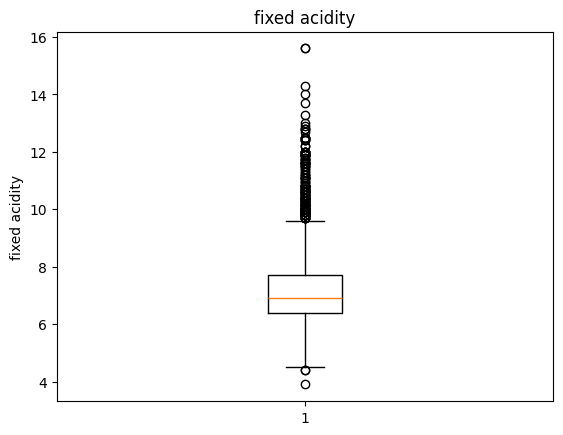

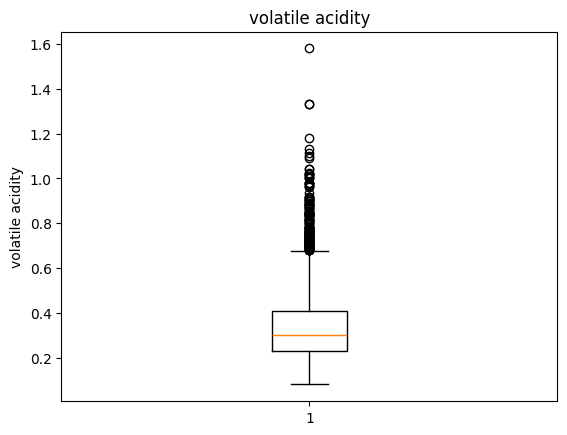

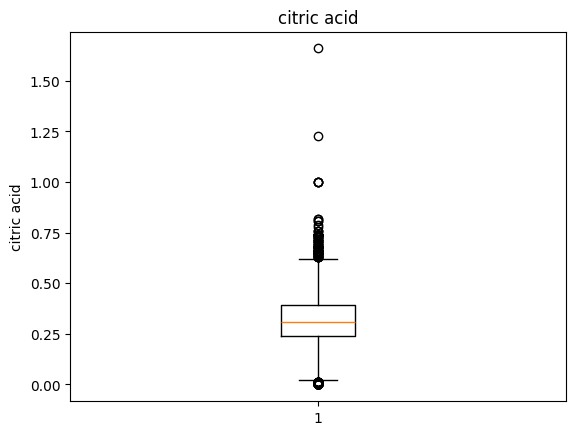

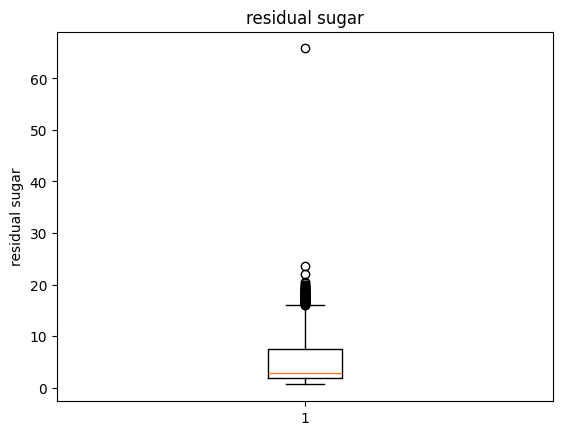

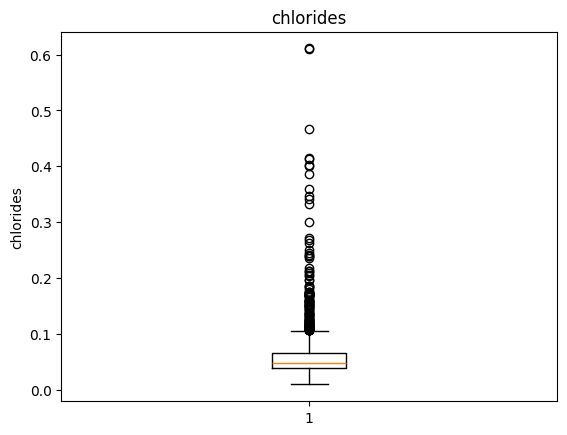

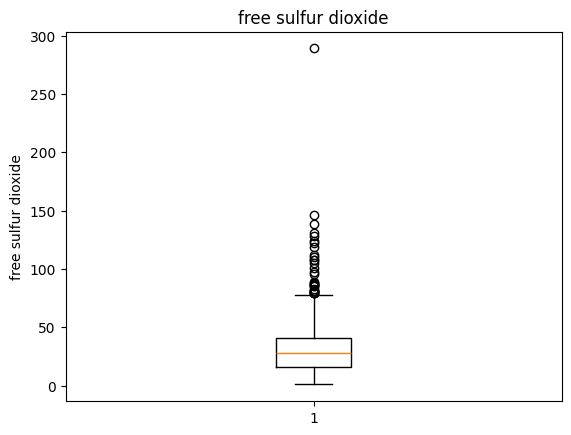

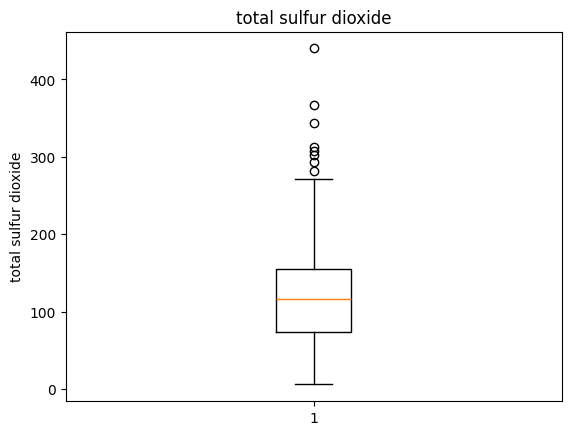

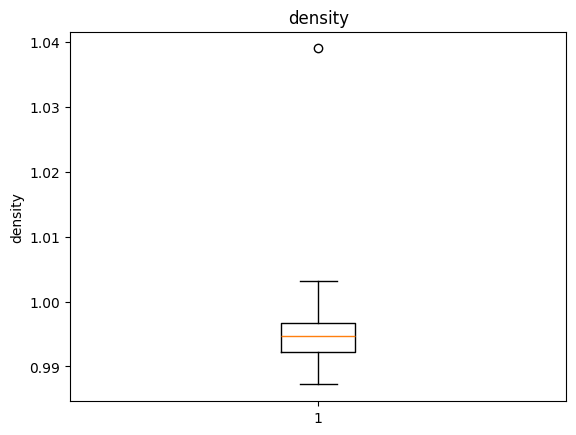

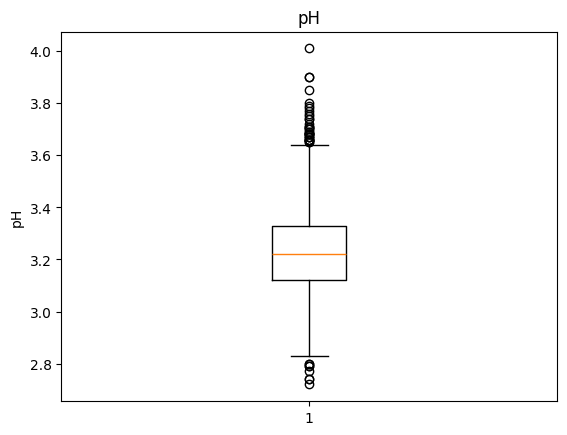

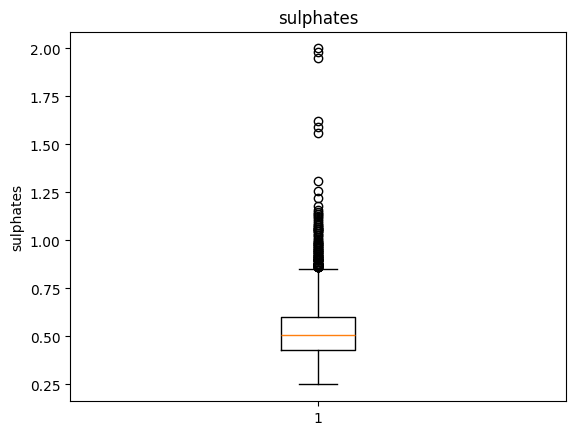

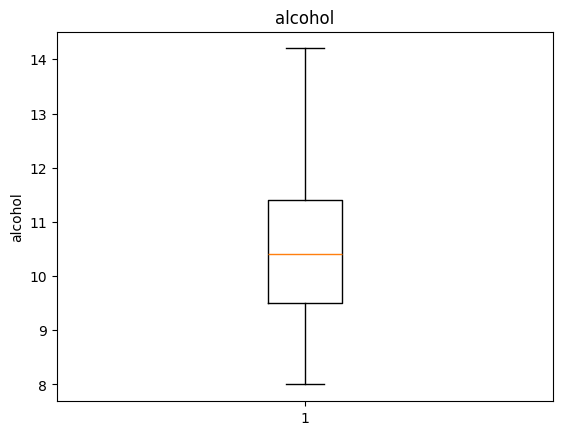

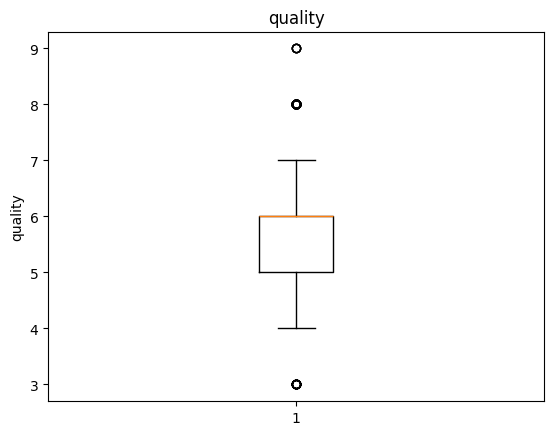

In [5]:
# Много выбросов
num_cols = df.select_dtypes(include="number").columns
for col in num_cols:
    plt.figure()
    plt.boxplot(df[col])
    plt.title(col)
    plt.ylabel(col)
    plt.show()

In [6]:
Q1, Q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
IQR = Q3 - Q1
mask = (df[num_cols] < (Q1 - 1.5*IQR)) | (df[num_cols] > (Q3 + 1.5*IQR))

print("Количество выбросов в каждом столбце")
print(mask.sum().sort_values(ascending=False))

Количество выбросов в каждом столбце
citric acid             223
fixed acidity           171
volatile acidity        169
chlorides               146
quality                 108
sulphates               104
residual sugar           86
pH                       43
free sulfur dioxide      32
total sulfur dioxide      8
density                   1
alcohol                   0
dtype: int64


Правило 1,5 IQR отмечает редкие значения, но не доказывает ошибку измерения. Без сведений об ошибках оставим наблюдения и исходные оценки quality. Склонность дерева к переобучению будем контролировать параметрами модели.

In [7]:
# Сохраняем исходные значения признаков и quality.
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,3192.0,7.196413,1.282733,3.90000,6.4000,6.90000,7.700000,15.60000
volatile acidity,3192.0,0.345515,0.170873,0.08000,0.2300,0.30000,0.410000,1.58000
citric acid,3192.0,0.316773,0.150347,0.00000,0.2400,0.31000,0.392500,1.66000
residual sugar,3192.0,5.067011,4.548557,0.60000,1.8000,2.80000,7.500000,65.80000
chlorides,3192.0,0.056335,0.036254,0.00900,0.0380,0.04700,0.065000,0.61100
free sulfur dioxide,3192.0,30.247180,18.565375,1.00000,16.0000,28.00000,41.000000,289.00000
total sulfur dioxide,3192.0,114.675752,57.427871,6.00000,74.0000,117.00000,155.000000,440.00000
density,3192.0,0.994537,0.002982,0.98722,0.9922,0.99464,0.996725,1.03898
pH,3192.0,3.227102,0.161596,2.72000,3.1200,3.22000,3.330000,4.01000
sulphates,3192.0,0.534887,0.152340,0.25000,0.4300,0.51000,0.600000,2.00000


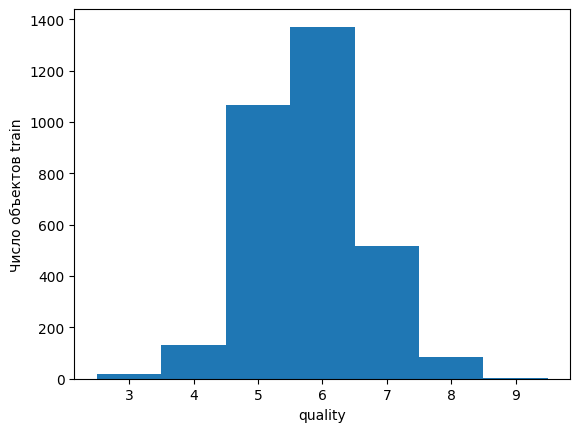

In [8]:
plt.hist(df['quality'], bins=np.arange(2.5, 10.5, 1))
plt.xlabel('quality')
plt.ylabel('Число объектов train')
plt.show()

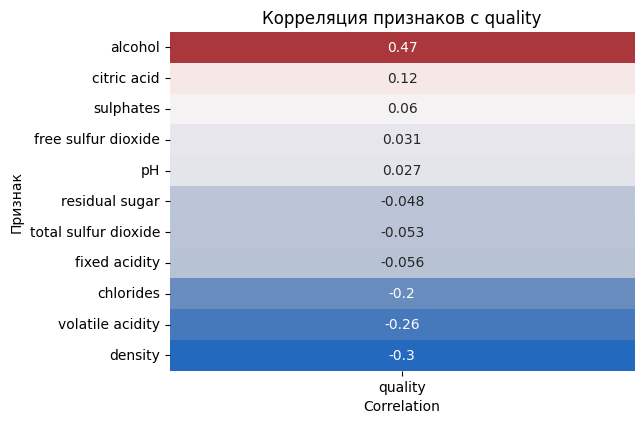

In [9]:
# 1. Считаем матрицу корреляций
corr = df.corr(numeric_only=True)

# 2. Берём только столбец quality, убираем строку quality и сортируем
corr_q = corr["quality"].drop("quality").sort_values(ascending=False)

# 3. Рисуем теплокарту
plt.figure(figsize=(6, len(corr_q) * 0.4))
sns.heatmap(corr_q.to_frame(), annot=True, cmap="vlag", cbar=False)
plt.title("Корреляция признаков с quality")
plt.ylabel("Признак")
plt.xlabel("Correlation")
plt.show()

In [10]:
# Два заранее известных типа вина кодируем одинаково во всех частях.
for frame in [df, df_val, df_holdout]:
    frame['type_white'] = (frame['type'] == 'white').astype(int)
    frame.drop(columns='type', inplace=True)
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type_white
4636,6.9,0.380,0.28,8.30,0.062,22.0,166.0,0.99506,3.16,0.72,10.6,5,1
1685,6.3,0.390,0.35,5.90,0.040,82.5,260.0,0.99410,3.12,0.66,10.1,5,1
2373,6.8,0.180,0.37,1.50,0.027,37.0,93.0,0.99200,3.30,0.45,10.8,6,1
5311,4.9,0.235,0.27,11.75,0.030,34.0,118.0,0.99540,3.07,0.50,9.4,6,1
951,5.6,0.660,0.00,2.50,0.066,7.0,15.0,0.99256,3.52,0.58,12.9,5,0


In [11]:
X = df.drop(["quality"], axis=1)
y = df["quality"]

In [12]:
X_train, y_train = X, y
X_val, y_val = df_val.drop(columns='quality'), df_val['quality']
X_holdout, y_holdout = df_holdout.drop(columns='quality'), df_holdout['quality']
print('Train / validation / test:', len(X_train), len(X_val), len(X_holdout))

Train / validation / test: 3192 1064 1064


### Задача 1. `sklearn`: неограниченное дерево [1 балл]  

Работаем с датасетом Wine Quality. Будем предсказывать оценку качества вина.

  




#### Задача 1.1 [0,5 балла]

- Обучи неограниченное дерево `DecisionTreeRegressor(random_state=42)` и выведи $R^2$ на validation.

- Выведи глубину дерева и число листьев.

In [17]:
# Напиши код здесь
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

R2 = model.score(X_val, y_val)
print(f'R2 = {R2:.3f}')

#Выведи глубину дерева и число листьев
print(f'Глубина дерева: {model.get_depth()}')
print(f'Число листьев: {model.get_n_leaves()}')

R2 = 0.528
Глубина дерева: 3
Число листьев: 8


#### Задача 1.2 [0,5 балла]

Отрисуй первые три уровня полученного дерева с помощью `plot_tree` (параметр `max_depth = 2`).

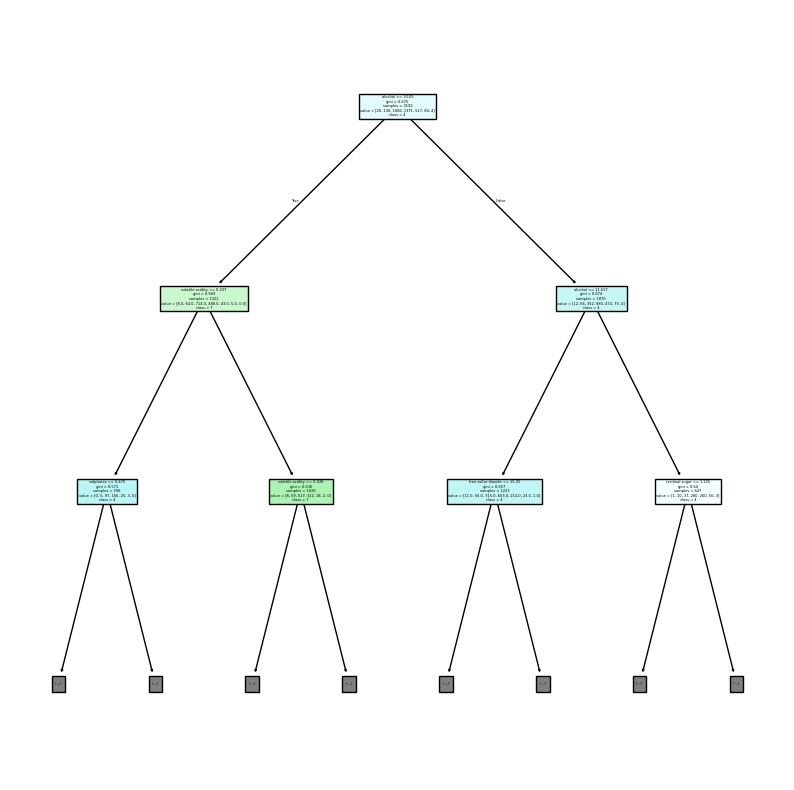

In [23]:
#Отрисуй первые три уровня полученного дерева с помощью `plot_tree` (параметр `max_depth = 2`)
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

plt.figure(figsize=(10, 10))
tree.plot_tree(model, max_depth=2, feature_names=df.columns, class_names=df["quality"].unique().astype(str), filled=True)
plt.show()

### Задача 2. `sklearn`: ограниченное дерево [2 балла]  

Сравни неограниченное дерево с деревьями меньшей сложности на общей validation. Не используй итоговый test для выбора параметров.

#### Задача 2.1 [0,5 балла]

- Напиши цикл, который будет проходить по различным значениям `max_depth` (от 1 до 23).

- Для каждого значения глубины обучи `DecisionTreeRegressor` с заданной глубиной на обучающих данных.

- Вычисли $R^2$ только на валидационной выборке.

- Нарисуй график зависимости валидационного $R^2$ от глубины дерева.

max_depth = 1, R^2 = 0.15304404680387884
max_depth = 2, R^2 = 0.2182842870598558
max_depth = 3, R^2 = 0.2500448861434915
max_depth = 4, R^2 = 0.2786579114744949
max_depth = 5, R^2 = 0.27523369133541786
max_depth = 6, R^2 = 0.28636556197589946
max_depth = 7, R^2 = 0.23317687656439723
max_depth = 8, R^2 = 0.22726792878806745
max_depth = 9, R^2 = 0.19833778815003955
max_depth = 10, R^2 = 0.1259957723233328
max_depth = 11, R^2 = 0.07716127621651181
max_depth = 12, R^2 = -0.02366796539830207
max_depth = 13, R^2 = -0.09006904691421846
max_depth = 14, R^2 = -0.20770022882946404
max_depth = 15, R^2 = -0.1999191688621591
max_depth = 16, R^2 = -0.20409099569436018
max_depth = 17, R^2 = -0.2350423633264329
max_depth = 18, R^2 = -0.33583303104121165
max_depth = 19, R^2 = -0.20969242956368683
max_depth = 20, R^2 = -0.28854439339032867
max_depth = 21, R^2 = -0.23259075947123042
max_depth = 22, R^2 = -0.26811715721739615
max_depth = 23, R^2 = -0.24899981313874187


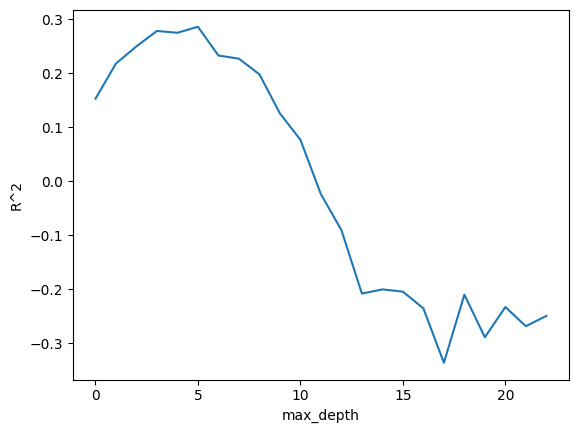

In [27]:
# Напиши код здесь
r2_scores = []
for i in range(1, 24):
    model = DecisionTreeRegressor(max_depth=i)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    r2 = r2_score(y_val, y_pred)
    r2_scores.append(r2)
    print(f"max_depth = {i}, R^2 = {r2}")


# Нарисуй график зависимости валидационного $R^2$ от глубины дерева.

%matplotlib inline
plt.plot(range(0, 23), r2_scores)
plt.xlabel("max_depth")
plt.ylabel("R^2")
plt.show()



#### Задача 2.2 [0,5 балла]  

- Напиши аналогичный цикл для гиперпараметра `min_samples_split`. Массив значений, которые надо проверить: `splits = [10, 20, 50, 100, 150, 200, 300, 400, 500, 600, 700, 1000, 1500, 2000]`.

- Нарисуй аналогичный график.

max_depth = 23, R^2 = -0.057126528964800416
max_depth = 23, R^2 = 0.03700648462540279
max_depth = 23, R^2 = 0.1853939344258756
max_depth = 23, R^2 = 0.24034431476794682
max_depth = 23, R^2 = 0.2599828121529657
max_depth = 23, R^2 = 0.272851243638473
max_depth = 23, R^2 = 0.2683606449502649
max_depth = 23, R^2 = 0.2688185504035897
max_depth = 23, R^2 = 0.2573294230508465
max_depth = 23, R^2 = 0.2601162087492894
max_depth = 23, R^2 = 0.2601162087492894
max_depth = 23, R^2 = 0.24790675357399483
max_depth = 23, R^2 = 0.2116979928367536
max_depth = 23, R^2 = 0.2116979928367536


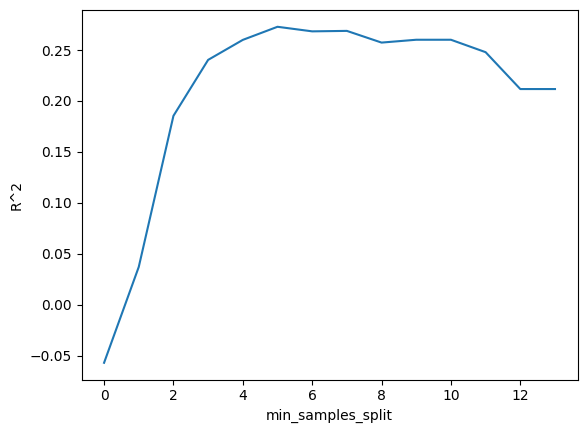

In [ ]:
# Напиши код здесь
# Напиши код здесь
splits = [10, 20, 50, 100, 150, 200, 300, 400, 500, 600, 700, 1000, 1500, 2000]

r2_scores = []
for split in splits:
    model = DecisionTreeRegressor(min_samples_split=split)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    r2 = r2_score(y_val, y_pred)
    r2_scores.append(r2)
    print(f"max_depth = {i}, R^2 = {r2}")


# Нарисуй график зависимости валидационного $R^2$ от глубины дерева.

%matplotlib inline
plt.plot(range(0, len(splits)), r2_scores)
plt.xlabel("min_samples_split")
plt.ylabel("R^2")
plt.show()

#### Задача 2.3 [0,5 балла]

**Вопрос.** Как можно объяснить два нарисованных графика?
Графики из заданий 2.1 и 2.2 иллюстрируют классическую проблему недообучения  и переобучениярешающего дерева при изменении его гиперпараметров
Первый график: При совсем небольшой глубине (1–3) дереву не хватает ветвей и условий, чтобы уловить сложные закономерности в данных. С дальнейшим ростом глубины график $R^{2}$ стремительно падает вниз, уходя глубоко в отрицательные значения.

Второй график: Здесь ситуация выглядит зеркально, поскольку этот параметр работает в противоположную сторону (чем больше значение, тем сильнее регуляризация и проще модель).

#### Задача 2.4 [0,5 балла]

Подбери гиперпараметры с Optuna, максимизируя средний R² по `KFold(n_splits=5, shuffle=True, random_state=42)` на train. Используй до 300 попыток и 600 секунд. Для воспроизводимости задай `TPESampler(seed=42)`. После поиска выведи `study.best_params` и `study.best_value`.

In [33]:
!pip3 install optuna --quiet

import optuna
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


/Users/d.churikov/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Напиши код здесь
import optuna
def objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 1, 10),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None]),
        'criterion': trial.suggest_categorical('criterion', ['squared_error', 'friedman_mse', 'absolute_error', 'poisson'])
    }
    model = DecisionTreeRegressor(**params, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=KFold(n_splits=5, shuffle=True, random_state=42), scoring='r2')
    return scores.mean()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=300, timeout=600)
print(study.best_params)
print(study.best_value)

[I 2026-10-25 18:52:49,459] A new study created in memory with name: no-name-f0fa6bec-acda-464a-8e7f-06e2a7c3c4ae
[I 2026-10-25 18:52:49,510] Trial 0 finished with value: 0.16751743644708655 and parameters: {'max_depth': 4, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'criterion': 'friedman_mse'}. Best is trial 0 with value: 0.16751743644708655.
[I 2026-10-25 18:52:49,528] Trial 1 finished with value: 0.08660320002753127 and parameters: {'max_depth': 1, 'min_samples_split': 10, 'min_samples_leaf': 9, 'max_features': 'sqrt', 'criterion': 'friedman_mse'}. Best is trial 0 with value: 0.16751743644708655.
[I 2026-10-25 18:52:50,315] Trial 2 finished with value: 0.12796334489829644 and parameters: {'max_depth': 7, 'min_samples_split': 3, 'min_samples_leaf': 3, 'max_features': None, 'criterion': 'absolute_error'}. Best is trial 0 with value: 0.16751743644708655.
[I 2026-10-25 18:52:50,629] Trial 3 finished with value: 0.041914415699103945 and parameters: {'max_dept

{'max_depth': 4, 'min_samples_split': 3, 'min_samples_leaf': 8, 'max_features': None, 'criterion': 'friedman_mse'}
0.2489611407933789


### Задача 3. Свой `DecisionTreeRegressor` [2 балла]  

Задача 3 состоит из трёх подзадач. В подзадаче 3.1 и 3.2 ты напишешь методы класса, а в подзадаче 3.3 вставишь эти методы в скелет класса. Этот скелет моделирует работу деревьев регрессии. Твоя цель — дописать в этот класс два метода (из подзадач 3.1 и 3.2), которые позволяют дереву расти.



In [36]:
# Вспомогательные функции и классы
from dataclasses import dataclass

def rss(y):
    """Residual Sum of Squares."""
    y = np.asarray(y)
    mu = y.mean()
    return np.sum((y - mu) ** 2)

@dataclass
class NodeR:
    feat: int = None
    thr: float = None
    left: "NodeR" = None
    right: "NodeR" = None
    value: float = None

In [37]:
# Меняем только представление данных. Разбиение сохраняется.
X_train = np.asarray(X_train, dtype=float)
X_val = np.asarray(X_val, dtype=float)
X_holdout = np.asarray(X_holdout, dtype=float)
y_train, y_val, y_holdout = map(np.asarray, (y_train, y_val, y_holdout))

#### Задача 3.1 [1 балл]

- Реализуй метод `_best_split(X, y, feat_idxs)`. Метод на данном шаге ищет признак и порог, минимизирующие сумму RSS в дочерних узлах.

- Используй уже написанный метод RSS, рассчитывающий сумму квадратов остатков предсказаний.

In [38]:
# Зададим какой-то гиперпараметр min_samples_leaf
min_samples_leaf = 500

# Напиши код здесь
# Перед тем, как начать заполнять функцию, вспомни теорию построения дерева из
# лонгрида и продумай алгоритм построения дерева регрессии

# feat_idxs — номера столбцов (признаков)
# Х и у — наблюдения в текущем узле
def _best_split(X, y, feat_idxs):
    # Лучший признак по которому надо делить, лучший порог, лучшая мера неопределённости
    best_feat, best_thr, best_rss = None, None, np.inf
    n = len(y)

    # Для каждого признака выполняем
    for f in feat_idxs:
        # Сортируй по текущему признаку
        # Сортировка позволит «идти» слева направо по значениям признака и выбирать порог
        # https://numpy.org/devdocs/reference/generated/numpy.argsort.html

        order = np.argsort(X[:, f])
        x_sorted = X[order, f]
        y_sorted = y[order]

        # Идём слева направо и смотрим на результативность порогов признака
        for i in range(min_samples_leaf,
                        n - min_samples_leaf + 1):
            # Напиши if, который сработает, если два разных наблюдения будут иметь
            # одно и то же значение признака. Нужно ли тогда повторно проверять
            # результативность применения одного и того же порога признака?

            if x_sorted[i - 1] == x_sorted[i]:
                continue

            left_y  = y_sorted[:i]
            right_y = y_sorted[i:]

            # Напиши, чему будет равен общий RSS двух потомственных сплитов. Нужна ли здесь нормировка?
            # Ответ: Общий RSS равен сумме RSS левого и правого поддеревьев. 
            # Нормировка здесь не обязательна, так как общее число элементов n фиксировано на данном шаге.
            
            total_rss = rss(left_y) + rss(right_y)
            if total_rss < best_rss:
                best_rss = total_rss
                best_feat = f
                best_thr = (x_sorted[i - 1] + x_sorted[i]) / 2
                
    return best_feat, best_thr

#### Задача 3.2 [1 балл]

Реализуй рекурсивный метод `_fit_node(X, y, depth)`, который строит всё дерево.    

In [ ]:
# Зададим гиперпараметры
max_depth = 5
min_samples_split = 500

# Напиши код здесь

# Сейчас мы используем предыдущую функцию для того, чтобы рекурсивно построить дерево
# X, y — наблюдения в текущем узле, в начале подаётся полный датасет
# depth = 0 в начале, по мере роста дерева увеличивается
def _fit_node(X, y, depth):
    # Создаем узел
    node = NodeR()
    n = len(y)

    # Напиши стоп-условия, которые остановят рост дерева и вернут значение листа
    # Подсказка: стоп-условия связаны с гиперпараметрами выше

    if (depth >= max_depth) or (n < min_samples_split) or (np.unique(y).size == 1):
        node.value = y.mean()
        return node

    # Реализуй функцию _best_split()
    feat_idxs = range(X.shape[1])
    feat, thr = _best_split(X, y, feat_idxs)

    if feat is None:     # Если сплит не найден
        node.value = y.mean()
        return node

    node.feat, node.thr = feat, thr
    mask = X[:, feat] <= thr

    # Реализуй рекурсивную функцию _fit_node, которая будет делить узел на два
    # подузла и для каждого подузла реализовывать тот же функционал

    node.left  = _fit_node(X[mask], y[mask], depth + 1)
    node.right = _fit_node(X[~mask], y[~mask], depth + 1)
    return node

#### Задача 3.3 [Обязательная]

Перенеси функции из 3.1 и 3.2 в методы `MyDecisionTreeRegressor`. Добавь `self` и используй `self.min_samples_leaf`, `self.min_samples_split`, `self.max_depth`, `self.rss`.

Обучи класс на прежнем train и рассчитай R² на validation. Сравни со sklearn при одинаковых `max_depth=5`, `min_samples_split=2`, `min_samples_leaf=1`.

Сборка класса обязательна: без неё максимум за задачу 3 составляет 1 балл. Без оценки на validation максимум составляет 1,5 балла.

In [40]:
from dataclasses import dataclass

@dataclass
class NodeR:
    feat: int = None
    thr: float = None
    left: "NodeR" = None
    right: "NodeR" = None
    value: float = None


class MyDecisionTreeRegressor:
    def __init__(self, max_depth=5, min_samples_split=2,
                 min_samples_leaf=1, random_state=None):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state  # В этой реализации разбиения детерминированы
        self.root = None

    @staticmethod
    def rss(y):
        """Residual Sum of Squares."""
        mu = y.mean()
        return np.sum((y - mu) ** 2)

    # ---------- 3.1 ----------
    def _best_split(self, X, y, feat_idxs):
        # Напиши функцию здесь
        best_feat, best_thr, best_rss = None, None, np.inf
        n = len(y)

        for f in feat_idxs:
            order = np.argsort(X[:, f])
            x_sorted = X[order, f]
            y_sorted = y[order]
            
            for i in range(self.min_samples_leaf, n - self.min_samples_leaf + 1):
                if x_sorted[i - 1] == x_sorted[i]:
                    continue
                    
                left_y = y_sorted[:i]
                right_y = y_sorted[i:]
                
                total_rss = self.rss(left_y) + self.rss(right_y)
                
                if total_rss < best_rss:
                    best_rss = total_rss
                    best_feat = f
                    best_thr = (x_sorted[i - 1] + x_sorted[i]) / 2
                    
        return best_feat, best_thr

    # ---------- 3.2 ----------
    def _fit_node(self, X, y, depth):
        # Напиши функцию здесь
        node = NodeR()
        n = len(y)

        # Проверка базовых условий остановки рекурсии
        if (depth >= self.max_depth) or (n < self.min_samples_split) or (np.unique(y).size == 1):
            node.value = y.mean() if n > 0 else 0.0
            return node

        feat_idxs = range(X.shape[1])
        feat, thr = self._best_split(X, y, feat_idxs)

        if feat is None:     
            node.value = y.mean()
            return node

        node.feat, node.thr = feat, thr
        mask = X[:, feat] <= thr

        node.left  = self._fit_node(X[mask], y[mask], depth + 1)
        node.right = self._fit_node(X[~mask], y[~mask], depth + 1)
        return node

    # ---- Публичные методы fit/predict ----

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        self.root = self._fit_node(X, y, depth=0)
        return self

    def _predict_one(self, x, node):
        if node.left is None:
            return node.value
        return self._predict_one(x, node.left if x[node.feat] <= node.thr else node.right)

    def predict(self, X):
        if self.root is None:
            raise ValueError("Сначала вызови fit")
        return np.array([self._predict_one(x, self.root) for x in np.asarray(X)])

In [44]:
# Напиши функцию здесь
# Создай объект класса, обучи его и протестируй
params = {
    'max_depth': 5,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'random_state': 42
}
my_tree = MyDecisionTreeRegressor(**params)
my_tree.fit(X_train, y_train)
my_preds = my_tree.predict(X_val)
my_r2 = r2_score(y_val, my_preds)

Сравни R² учебной и библиотечной моделей на одинаковом разбиении. Близкие метрики сами по себе не доказывают совпадения деревьев. При равноценных разбиениях реализации могут выбрать разные признаки. Для проверки алгоритма нужны также небольшие примеры с известным оптимальным порогом. После этого однократно оцени выбранное Optuna дерево на test, не меняя настройки по результату.

In [45]:
sk_tree = DecisionTreeRegressor(**params)
sk_tree.fit(X_train, y_train)
sk_preds = sk_tree.predict(X_val)
sk_r2 = r2_score(y_val, sk_preds)

print(f"R² MyDecisionTreeRegressor: {my_r2:.5f}")
print(f"R² sklearn DecisionTreeRegressor: {sk_r2:.5f}")
print(f"Разница в предсказаниях (MAE между моделями): {np.abs(my_preds - sk_preds).mean():.5e}")

R² MyDecisionTreeRegressor: 0.27523
R² sklearn DecisionTreeRegressor: 0.27523
Разница в предсказаниях (MAE между моделями): 0.00000e+00


In [50]:
sk_tree = DecisionTreeRegressor(**study.best_params)
sk_tree.fit(X_train, y_train)
sk_preds = sk_tree.predict(X_val)
sk_r2 = r2_score(y_val, sk_preds)
print(f"best_params R² MyDecisionTreeRegressor: {my_r2:.5f}")

best_params R² MyDecisionTreeRegressor: 0.27523


## Часть II. Деревья классификации

Для второй части домашнего задания тебе понадобится [датасет Adult](https://archive.ics.uci.edu/dataset/2/adult) (`adult`).

Датасет Adult (он же Census Income) — классический набор данных, собранный во время переписи населения США 1994 года. В нём около 48 000 записей и 14 признаков: возраст, род занятий, уровень образования, семейный статус, профессия, родственники в семье, раса, пол, доходы от капитала, убытки от капитала, количество рабочих часов в неделю и страна рождения. Целевая метка — бинарная: получает человек более 50 000 $ в год или нет.

Чаще всего Adult используют для обучения и сравнения бинарных классификаторов (логистическая регрессия, деревья решений, бустинг), а ещё как тест на обработку категориальных признаков (one-hot, целевое кодирование) и работу с пропущенными значениями (в датасете некоторые поля обозначены `?`). Класс `>50K` составляет около четверти выборки, что даёт умеренный дисбаланс и повод поэкспериментировать с метриками (precision/recall, ROC-AUC).




In [51]:
# Импорт библиотек
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import seaborn as sns

In [52]:
# 1. Список имён колонок из adult.names
columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

# 2. URL-адреса
train_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
test_url  = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

# 3. Скачиваем и читаем
df_train = pd.read_csv(
    train_url,
    names=columns,
    sep=',',
    na_values='?',
    skipinitialspace=True
)
df_test = pd.read_csv(
    test_url,
    names=columns,
    sep=',',
    na_values='?',
    skipinitialspace=True,
    skiprows=1  # Пропустить строку заголовка в файле .test
)

# В учебном эксперименте используем собственное разбиение объединённых данных.
# Это не оценка на официальном test-разбиении Adult.
df = pd.concat([df_train, df_test], ignore_index=True)
df['income'] = df['income'].str.strip().str.rstrip('.')
df = df.drop_duplicates().reset_index(drop=True)
df_dev, df_holdout = train_test_split(df, test_size=0.2, random_state=42, stratify=df['income'])
df, df_val = train_test_split(df_dev, test_size=0.25, random_state=42, stratify=df_dev['income'])
df, df_val, df_holdout = df.copy(), df_val.copy(), df_holdout.copy()

In [53]:
num_cols = df.select_dtypes('number').columns
cat_cols = df.select_dtypes('object').columns.drop('income')

In [54]:
print(df.shape)
df.head()

(29274, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
48110,66,Private,171824,Some-college,10,Never-married,Prof-specialty,Not-in-family,White,Female,0,0,15,United-States,<=50K
17433,35,Self-emp-not-inc,264627,11th,7,Divorced,Exec-managerial,Unmarried,White,Female,0,0,84,United-States,<=50K
17524,21,NaN,121694,7th-8th,4,Never-married,NaN,Own-child,White,Male,0,0,40,United-States,<=50K
33936,34,Private,24361,Prof-school,15,Never-married,Prof-specialty,Not-in-family,White,Female,10520,0,40,United-States,>50K
8457,40,Self-emp-not-inc,125206,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,40,United-States,<=50K


Начнём с изучения целевой переменной.

In [55]:
df['income']

48110    <=50K
17433    <=50K
17524    <=50K
33936     >50K
8457     <=50K
         ...  
25463    <=50K
825       >50K
47714    <=50K
31369     >50K
3625     <=50K
Name: income, Length: 29274, dtype: object

In [56]:
df['income'] = df['income'].str.strip().str.rstrip('.')

income
<=50K    0.760573
>50K     0.239427
Name: proportion, dtype: float64


<Axes: xlabel='income'>

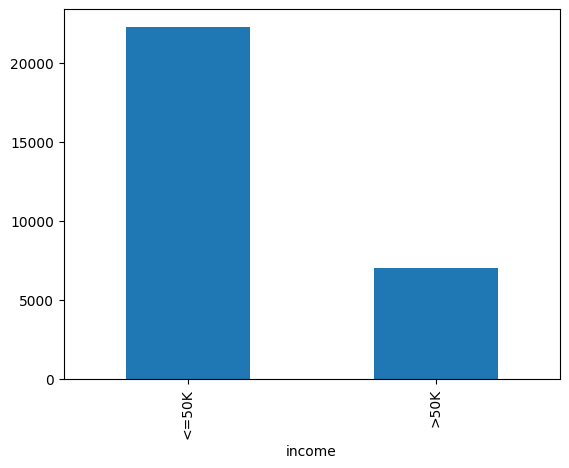

In [57]:
print(df['income'].value_counts(normalize=True))
df['income'].value_counts().plot(kind='bar')

В дальнейшем будем учитывать, что в датасете гораздо больше людей с доходом `<=50K ` (то есть классы несбалансированы).


Теперь посмотрим на пропуски.

In [58]:
for frame in [df, df_val, df_holdout]:
    frame.replace('?', np.nan, inplace=True)

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 29274 entries, 48110 to 3625
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             29274 non-null  int64 
 1   workclass       27625 non-null  object
 2   fnlwgt          29274 non-null  int64 
 3   education       29274 non-null  object
 4   education_num   29274 non-null  int64 
 5   marital_status  29274 non-null  object
 6   occupation      27620 non-null  object
 7   relationship    29274 non-null  object
 8   race            29274 non-null  object
 9   sex             29274 non-null  object
 10  capital_gain    29274 non-null  int64 
 11  capital_loss    29274 non-null  int64 
 12  hours_per_week  29274 non-null  int64 
 13  native_country  28769 non-null  object
 14  income          29274 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.6+ MB


In [60]:
for frame in [df, df_val, df_holdout]:
    frame[cat_cols] = frame[cat_cols].fillna('Unknown')

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 29274 entries, 48110 to 3625
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             29274 non-null  int64 
 1   workclass       29274 non-null  object
 2   fnlwgt          29274 non-null  int64 
 3   education       29274 non-null  object
 4   education_num   29274 non-null  int64 
 5   marital_status  29274 non-null  object
 6   occupation      29274 non-null  object
 7   relationship    29274 non-null  object
 8   race            29274 non-null  object
 9   sex             29274 non-null  object
 10  capital_gain    29274 non-null  int64 
 11  capital_loss    29274 non-null  int64 
 12  hours_per_week  29274 non-null  int64 
 13  native_country  29274 non-null  object
 14  income          29274 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.6+ MB


In [62]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,29274.0,38.635239,13.683875,17.0,28.0,37.0,48.00,90.0
fnlwgt,29274.0,189720.486712,105470.446951,12285.0,117767.0,178109.0,237871.75,1490400.0
education_num,29274.0,10.071360,2.575409,1.0,9.0,10.0,12.00,16.0
capital_gain,29274.0,1048.380782,7323.276125,0.0,0.0,0.0,0.00,99999.0
capital_loss,29274.0,86.453406,399.897443,0.0,0.0,0.0,0.00,4356.0
hours_per_week,29274.0,40.536961,12.463249,1.0,40.0,40.0,45.00,99.0


In [63]:
# Есть ли опечатки в названиях категорий? Редкие категории?
for col in cat_cols:
    print('\n', col)
    display(df[col].value_counts().head(10))


 workclass


workclass
Private             20300
Self-emp-not-inc     2325
Local-gov            1896
Unknown              1649
State-gov            1163
Self-emp-inc         1018
Federal-gov           903
Without-pay            15
Never-worked            5
Name: count, dtype: int64


 education


education
HS-grad         9503
Some-college    6491
Bachelors       4794
Masters         1599
Assoc-voc       1214
11th            1077
Assoc-acdm       946
10th             846
7th-8th          592
Prof-school      493
Name: count, dtype: int64


 marital_status


...

race
White                 25001
Black                  2827
Asian-Pac-Islander      931
Amer-Indian-Eskimo      272
Other                   243
Name: count, dtype: int64


 sex


sex
Male      19656
Female     9618
Name: count, dtype: int64


 native_country


native_country
United-States    26295
Mexico             570
Unknown            505
Philippines        188
Germany            123
Puerto-Rico        113
Canada              96
El-Salvador         88
Cuba                87
India               84
Name: count, dtype: int64

Большое число категорий увеличивает размер one-hot представления. Объединим категории, которые занимают меньше 1% train, и применим те же правила к отложенным данным.

In [64]:
cat_cols = df.select_dtypes('object').columns.drop('income')
for col in cat_cols:
    counts = df[col].str.strip().value_counts()
    frequent = counts[counts >= 0.01*len(df)].index
    for frame in [df, df_val, df_holdout]:
        values = frame[col].str.strip()
        frame[col] = values.where(values.isin(frequent), 'other')

In [65]:
cat_cols = df.select_dtypes('object').columns.drop('income')
for col in cat_cols:
    print('\n', col)
    display(df[col].value_counts().head(10))


 workclass


workclass
Private             20300
Self-emp-not-inc     2325
Local-gov            1896
Unknown              1649
State-gov            1163
Self-emp-inc         1018
Federal-gov           903
other                  20
Name: count, dtype: int64


 education


education
HS-grad         9503
Some-college    6491
Bachelors       4794
Masters         1599
Assoc-voc       1214
11th            1077
Assoc-acdm       946
10th             846
7th-8th          592
Prof-school      493
Name: count, dtype: int64


 marital_status


...

race
White                 25001
Black                  2827
Asian-Pac-Islander      931
other                   515
Name: count, dtype: int64


 sex


sex
Male      19656
Female     9618
Name: count, dtype: int64


 native_country


native_country
United-States    26295
other             1904
Mexico             570
Unknown            505
Name: count, dtype: int64

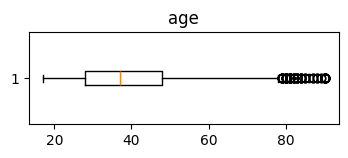

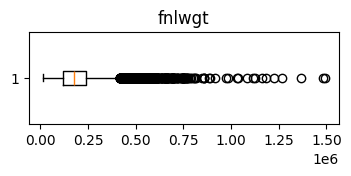

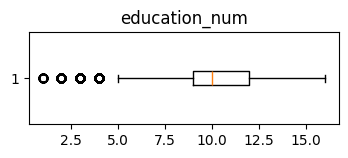

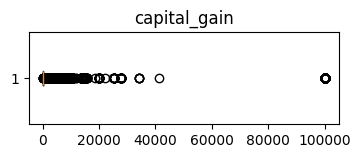

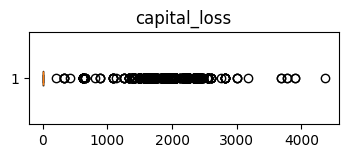

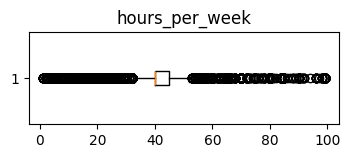

In [66]:
# Распределения числовых переменных
for col in num_cols:
    plt.figure(figsize=(4,1.2))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(col); plt.show()

In [67]:
(df['capital_gain'] > 0).astype(int).value_counts()

capital_gain
0    26898
1     2376
Name: count, dtype: int64

In [68]:
def add_features(frame):
    # age: разбиение на отрезки
    frame['age_bin'] = pd.cut(frame['age'], bins=[16,25,35,45,55,65,100],
                           labels=['17-25','26-35','36-45','46-55','56-65','66+'])

    # В этой модели исключаем вес переписного наблюдения fnlwgt.
    frame = frame.drop('fnlwgt', axis=1)

    # capital_gain/capital_loss → флаги
    frame['gain_flag'] = (frame['capital_gain'] > 0).astype(int)
    frame['loss_flag'] = (frame['capital_loss'] > 0).astype(int)

    # hours_per_week: разбиение на отрезки
    frame['hours_bin'] = pd.cut(frame['hours_per_week'],
                             bins=[0,40,55,168],
                             labels=['<=40','41-55','56+'])
    return frame

df, df_val, df_holdout = [add_features(frame) for frame in [df, df_val, df_holdout]]

In [69]:
# Проверим результат
df[['age','age_bin', 'capital_gain','gain_flag','capital_loss','loss_flag',
          'hours_per_week','hours_bin']].head()

,age,age_bin,capital_gain,gain_flag,capital_loss,loss_flag,hours_per_week,hours_bin
48110,66,66+,0,0,0,0,15,<=40
17433,35,26-35,0,0,0,0,84,56+
17524,21,17-25,0,0,0,0,40,<=40
33936,34,26-35,10520,1,0,0,40,<=40
8457,40,36-45,0,0,0,0,40,<=40


Выделим таргет отдельно от признаков. One-hot столбцы определим по train. Validation и test приведём к тем же столбцам, а отсутствующие заполним нулями.

In [70]:
y_train = (df['income'] == '>50K').astype(int)
y_val = (df_val['income'] == '>50K').astype(int)
y_holdout = (df_holdout['income'] == '>50K').astype(int)
X_train = pd.get_dummies(df.drop(columns='income'), dtype=int)
X_val = pd.get_dummies(df_val.drop(columns='income'), dtype=int).reindex(columns=X_train.columns, fill_value=0)
X_holdout = pd.get_dummies(df_holdout.drop(columns='income'), dtype=int).reindex(columns=X_train.columns, fill_value=0)
X_train.head()

,age,education_num,capital_gain,capital_loss,hours_per_week,gain_flag,loss_flag,workclass_Federal-gov,workclass_Local-gov,workclass_Private,...,native_country_other,age_bin_17-25,age_bin_26-35,age_bin_36-45,age_bin_46-55,age_bin_56-65,age_bin_66+,hours_bin_<=40,hours_bin_41-55,hours_bin_56+
48110,66,10,0,0,15,0,0,0,0,1,...,0,0,0,0,0,0,1,1,0,0
17433,35,7,0,0,84,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
17524,21,4,0,0,40,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
33936,34,15,10520,0,40,1,0,0,0,1,...,0,0,1,0,0,0,0,1,0,0
8457,40,15,0,0,40,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0


In [71]:
X_train.info(verbose=False)

<class 'pandas.core.frame.DataFrame'>
Index: 29274 entries, 48110 to 3625
Columns: 76 entries, age to hours_bin_56+
dtypes: int64(76)
memory usage: 17.2 MB


In [72]:
print("Число признаков:", X_train.shape[1])

Число признаков: 76


In [73]:
print('Train / validation / test:', len(X_train), len(X_val), len(X_holdout))

Train / validation / test: 29274 9758 9758


### Задача 4. `sklearn`: ограниченное дерево [2 балла]

Применим post-pruning. Сначала растёт полное дерево, затем из него удаляются ветви с учётом штрафа за число листьев. Параметр `ccp_alpha` управляет величиной этого штрафа. Последовательность допустимых значений возвращает `cost_complexity_pruning_path(X_train, y_train)`.

#### Задача 4.1 [1 балл]

Для критериев Джини и энтропии получи путь обрезки дерева на train. В этом эксперименте используй `class_weight='balanced'` и `random_state=42` во всех сравниваемых моделях.

Для каждого критерия возьми не более 300 равномерно расположенных индексов массива уникальных неотрицательных `ccp_alphas`. Если значений меньше 300, используй все. Для каждого alpha обучи дерево и рассчитай ROC-AUC по `predict_proba(X_val)[:, 1]`.

Сохрани `val_gini`, `val_entropy` той же длины, что соответствующие массивы alpha. Accuracy при дисбалансе может скрывать ошибки редкого класса. Здесь сравниваем ранжирование по ROC-AUC, а затем рассмотрим ошибки классов в confusion matrix. Сам дисбаланс не делает accuracy бессмысленной.

In [74]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

# Словари для сохранения результатов
alphas_dict = {}
roc_auc_results = {}

for criterion in ['gini', 'entropy']:
    # 1. Получаем путь обрезки (cost complexity pruning path)
    base_tree = DecisionTreeClassifier(
        criterion=criterion, 
        class_weight='balanced', 
        random_state=42
    )
    path = base_tree.cost_complexity_pruning_path(X_train, y_train)
    ccp_alphas = path.ccp_alphas
    
    # Оставляем только неотрицательные значения alpha
    ccp_alphas = ccp_alphas[ccp_alphas >= 0]
    # Удаляем дубликаты, если они есть, сохраняя порядок
    ccp_alphas = np.unique(ccp_alphas)
    
    # 2. Отбираем не более 300 равномерно расположенных индексов
    n_alphas = len(ccp_alphas)
    if n_alphas > 300:
        indices = np.linspace(0, n_alphas - 1, 300, dtype=int)
        ccp_alphas = ccp_alphas[indices]
    
    alphas_dict[criterion] = ccp_alphas
    val_scores = []
    
    # 3. Обучаем дерево для каждого alpha и считаем ROC-AUC
    for alpha in ccp_alphas:
        tree = DecisionTreeClassifier(
            criterion=criterion,
            class_weight='balanced',
            ccp_alpha=alpha,
            random_state=42
        )
        tree.fit(X_train, y_train)
        
        # Получаем вероятности для позитивного класса
        y_val_proba = tree.predict_proba(X_val)[:, 1]
        
        # Считаем метрику ROC-AUC
        score = roc_auc_score(y_val, y_val_proba)
        val_scores = np.append(val_scores, score)
        
    roc_auc_results[criterion] = val_scores

# Сохраняем результаты в требуемые переменные
val_gini = roc_auc_results['gini']
val_entropy = roc_auc_results['entropy']

# Выведем размерности для проверки и лучшие результаты
print(f"Размерность val_gini: {len(val_gini)} (Alpha: {len(alphas_dict['gini'])})")
print(f"Размерность val_entropy: {len(val_entropy)} (Alpha: {len(alphas_dict['entropy'])})")
print(f"Максимальный ROC-AUC (Gini): {val_gini.max():.4f} при alpha: {alphas_dict['gini'][val_gini.argmax()]:.6f}")
print(f"Максимальный ROC-AUC (Entropy): {val_entropy.max():.4f} при alpha: {alphas_dict['entropy'][val_entropy.argmax()]:.6f}")


Размерность val_gini: 300 (Alpha: 300)
Размерность val_entropy: 300 (Alpha: 300)
Максимальный ROC-AUC (Gini): 0.9094 при alpha: 0.000216
Максимальный ROC-AUC (Entropy): 0.9066 при alpha: 0.000510


#### Задача 4.2 [1 балл]

Построй validation ROC-AUC для всех проверенных alpha, включая значения с низким качеством. Чтобы различать малые alpha и сохранить alpha=0, используй `plt.xscale("symlog", linthresh=1e-5)`. Для каждого критерия выбери alpha по validation и построй confusion matrix на validation. Затем выбери один из двух вариантов по validation ROC-AUC, при равенстве оставь Gini. Однократно оцени его на test. По test больше не меняй alpha или критерий.

Лучший ROC-AUC (Gini) на validation: 0.9094 при alpha = 0.000216
Лучший ROC-AUC (Entropy) на validation: 0.9066 при alpha = 0.000510


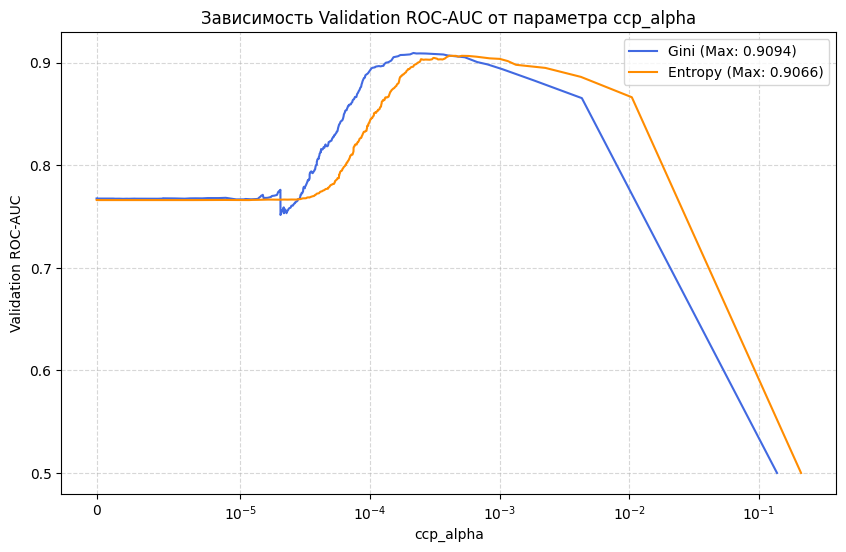

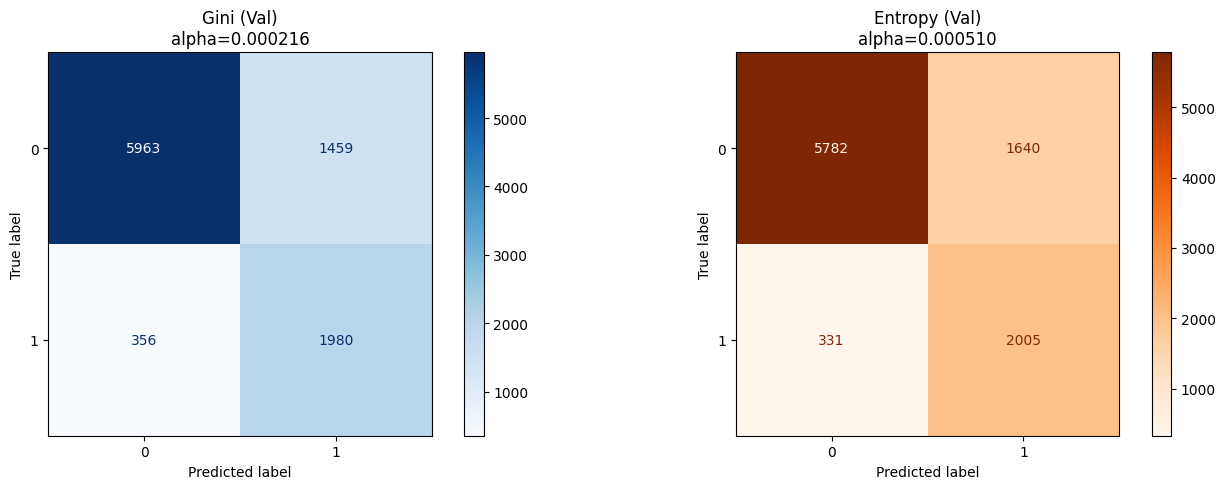

Выбран критерий: Gini (ROC-AUC 0.9094 >= Entropy 0.9066)

=== ИТОГОВЫЕ РЕЗУЛЬТАТЫ НА TEST (HOLDOUT) ===
Критерий: gini
Размер alpha: 0.000216
Финальный Test ROC-AUC: 0.9107


<Figure size 600x500 with 0 Axes>

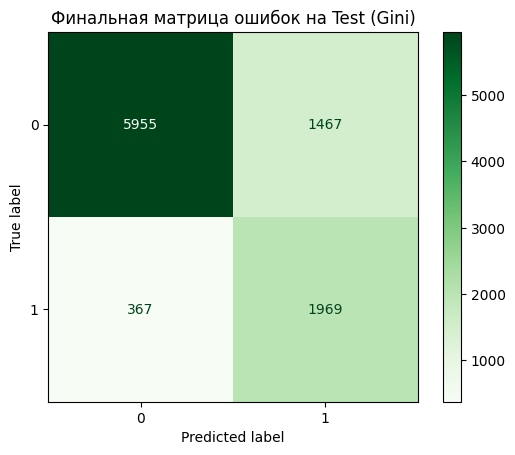

In [75]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Поиск оптимальных alpha по валидационной выборке
best_idx_gini = val_gini.argmax()
best_alpha_gini = alphas_dict['gini'][best_idx_gini]
best_score_gini = val_gini[best_idx_gini]

best_idx_entropy = val_entropy.argmax()
best_alpha_entropy = alphas_dict['entropy'][best_idx_entropy]
best_score_entropy = val_entropy[best_idx_entropy]

print(f"Лучший ROC-AUC (Gini) на validation: {best_score_gini:.4f} при alpha = {best_alpha_gini:.6f}")
print(f"Лучший ROC-AUC (Entropy) на validation: {best_score_entropy:.4f} при alpha = {best_alpha_entropy:.6f}")

# 2. Построение графика Validation ROC-AUC
plt.figure(figsize=(10, 6))
plt.plot(alphas_dict['gini'], val_gini, label=f"Gini (Max: {best_score_gini:.4f})", color='royalblue')
plt.plot(alphas_dict['entropy'], val_entropy, label=f"Entropy (Max: {best_score_entropy:.4f})", color='darkorange')

# Настройка оси X по вашему условию
plt.xscale("symlog", linthresh=1e-5)

plt.xlabel("ccp_alpha")
plt.ylabel("Validation ROC-AUC")
plt.title("Зависимость Validation ROC-AUC от параметра ccp_alpha")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.show()

# 3. Обучение моделей с лучшими alpha и построение Confusion Matrix на Validation
best_tree_gini = DecisionTreeClassifier(criterion='gini', class_weight='balanced', ccp_alpha=best_alpha_gini, random_state=42).fit(X_train, y_train)
best_tree_entropy = DecisionTreeClassifier(criterion='entropy', class_weight='balanced', ccp_alpha=best_alpha_entropy, random_state=42).fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_estimator(best_tree_gini, X_val, y_val, ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title(f"Gini (Val)\nalpha={best_alpha_gini:.6f}")

ConfusionMatrixDisplay.from_estimator(best_tree_entropy, X_val, y_val, ax=axes[1], cmap='Oranges', values_format='d')
axes[1].set_title(f"Entropy (Val)\nalpha={best_alpha_entropy:.6f}")
plt.tight_layout()
plt.show()

# 4. Выбор финальной модели (при равенстве оставляем Gini)
if best_score_entropy > best_score_gini:
    final_criterion = 'entropy'
    final_alpha = best_alpha_entropy
    final_model = best_tree_entropy
    print(f"Выбран критерий: Entropy (ROC-AUC {best_score_entropy:.4f} > Gini {best_score_gini:.4f})")
else:
    final_criterion = 'gini'
    final_alpha = best_alpha_gini
    final_model = best_tree_gini
    print(f"Выбран критерий: Gini (ROC-AUC {best_score_gini:.4f} >= Entropy {best_score_entropy:.4f})")

# 5. Однократная финальная оценка на Test (holdout)
y_holdout_proba = final_model.predict_proba(X_holdout)[:, 1]
test_roc_auc = roc_auc_score(y_holdout, y_holdout_proba)

print(f"\n=== ИТОГОВЫЕ РЕЗУЛЬТАТЫ НА TEST (HOLDOUT) ===")
print(f"Критерий: {final_criterion}")
print(f"Размер alpha: {final_alpha:.6f}")
print(f"Финальный Test ROC-AUC: {test_roc_auc:.4f}")

# Отрисовка матрицы ошибок на тесте
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(final_model, X_holdout, y_holdout, cmap='Greens', values_format='d')
plt.title(f"Финальная матрица ошибок на Test ({final_criterion.capitalize()})")
plt.show()


### Задача 5. Расширение `MyDecisionTreeClassifier` [2 балла]

В учебный класс добавим порог локального уменьшения неоднородности `min_gain` и веса классов. Этот порог останавливает рост дерева во время обучения и отличается от post-pruning через `ccp_alpha` в sklearn. Здесь `min_gain` относится к текущему узлу. Параметр `min_impurity_decrease` в sklearn дополнительно взвешивает уменьшение долей узла во всей обучающей выборке.

In [76]:
from typing import Optional, Union, Dict

class _Node:
    """Вершина дерева (и внутренний узел, и лист)."""
    def __init__(self, feat=None, thr=None, left=None, right=None,
                 proba=None, label=None):
        self.feat = feat      # Индекс признака для сплита
        self.thr = thr        # Порог сплита
        self.left = left      # Левая ветка
        self.right = right    # Правая ветка
        self.proba = proba    # Вероятности классов (только в листе)
        self.label = label    # Метка класса (только в листе)

    def is_leaf(self):
        """Возвращает True, если вершина является листом."""
        return self.label is not None


class MyDecisionTreeClassifier:
    """
    Мини-реализация дерева классификации (критерий Gini,
    бинарные сплиты по порогу).
    """

    def __init__(
        self,
        max_depth: Optional[int] = None,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        criterion: str = "gini",                     # #### NEW
        class_weight: Union[str, Dict[int, float], None] = None,  # #### NEW — твоё следующее задание
        min_gain: float = 0.0,                      # #### NEW — твоё следующее задание
        random_state: Optional[int] = None           # #### NEW
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion                   # #### NEW
        self.class_weight = class_weight             # #### NEW — твоё следующее задание
        self.min_gain = float(min_gain)            # #### NEW — твоё следующее задание
        self.random_state = random_state  # Разбиения перебираются детерминированно

    # ---------- Методы, реализованные вручную ----------
    def _make_leaf(self, y_subset: np.ndarray) -> _Node:
        """
        Превращает подмножество объектов в лист и
        возвращает объект `_Node` с полями `proba`, `label`.
        """
        counts = np.bincount(y_subset, weights=self.class_weights_[y_subset], minlength=self.n_classes_)
        proba  = counts / counts.sum()
        return _Node(proba=proba, label=int(proba.argmax()))

    def _predict_one(self, x_row: np.ndarray, node: _Node) -> int:
        """
        Спускает один объект по дереву до листа
        и возвращает предсказанный класс.
        """
        while not node.is_leaf():
            node = node.left if x_row[node.feat] <= node.thr else node.right
        return node.label

    def predict(self, X) -> np.ndarray:
        """
        Возвращает вектор прогнозов для всей матрицы `X`.

        Обрати внимание: мы сразу преобразуем X в numpy-массив,
        чтобы не индексировать строки как строки или pandas-объекты.
        """
        X_arr = np.asarray(X, dtype=float)
        return self.classes_[np.array([self._predict_one(row, self.root_) for row in X_arr])]

    # ----------------------------------------------------

    # ---------- Готовые вспомогательные методы ----------
    @staticmethod
    def _gini(counts: np.ndarray) -> float:
        p = counts / counts.sum()
        return 1.0 - (p ** 2).sum()

    @staticmethod
    def _entropy(counts: np.ndarray) -> float:             # NEW
        p = counts / counts.sum()
        p = p[p > 0]
        return -(p * np.log2(p)).sum()

    def _impurity(self, counts: np.ndarray) -> float:      # NEW
        return self._gini(counts) if self.criterion == "gini" else self._entropy(counts)

    def _best_split(self, X: np.ndarray, y: np.ndarray):
        """
        Перебирает все признаки и ищет порог,
        дающий максимальный прирост информации.
        Возвращает (feat, thr). Если сплита нет — (None, None).
        """
        best_gain, best_feat, best_thr = -np.inf, None, None
        parent_imp = self._impurity(np.bincount(y, weights=self.class_weights_[y], minlength=self.n_classes_))
        for feat in range(X.shape[1]):
            xs = X[:, feat]
            order = np.argsort(xs)
            xs_sort, y_sort = xs[order], y[order]
            right = np.bincount(y_sort, weights=self.class_weights_[y_sort], minlength=self.n_classes_).astype(float)
            left  = np.zeros_like(right)
            for i in range(1, len(y_sort)):
                cls = y_sort[i - 1]
                left[cls]  += self.class_weights_[cls]
                right[cls] -= self.class_weights_[cls]
                if xs_sort[i] == xs_sort[i - 1]:
                    continue
                if i < self.min_samples_leaf or len(y_sort) - i < self.min_samples_leaf:
                    continue
                wL = left.sum() / (left.sum() + right.sum())
                wR = 1 - wL
                gain = parent_imp - (wL * self._impurity(left) + wR * self._impurity(right))
                if gain > best_gain:
                    best_gain, best_feat = gain, feat
                    best_thr = (xs_sort[i] + xs_sort[i - 1]) / 2
        return best_feat, best_thr

    def _grow(self, X: np.ndarray, y: np.ndarray, depth: int = 0) -> _Node:
        """
        Рекурсивно строит дерево, возвращая корневой узел `_Node`.
        """
        if (self.max_depth is not None and depth == self.max_depth) or \
           len(np.unique(y)) == 1 or len(y) < self.min_samples_split:
            return self._make_leaf(y)

        feat, thr = self._best_split(X, y)
        if feat is None:
            return self._make_leaf(y)

        mask = X[:, feat] <= thr
        left  = self._grow(X[mask],  y[mask],  depth + 1)
        right = self._grow(X[~mask], y[~mask], depth + 1)
        return _Node(feat, thr, left, right)

    def fit(self, X, y):
        """
        Строит дерево по обучающим данным.
        Если `y` содержит строковые метки, сначала преобразует их в целые.
        """
        # Приводим X, y к numpy-массиву целых
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y)

        self.classes_, y_arr = np.unique(y_arr.ravel(), return_inverse=True)
        self.n_classes_ = len(self.classes_)
        self.class_weights_ = np.ones(self.n_classes_)

        self.root_ = self._grow(X_arr, y_arr)
        return self

Давай дополним этот класс.





#### Задача 5.1 [0,5 балла]

В `_best_split` используй выбранный `criterion` в родителе и обоих потомках. После поиска лучшего сплита верни `(None, None)`, если уменьшение взвешенной неоднородности не превосходит `self.min_gain`. Уменьшение здесь считается относительно текущего узла. При пороге 0 сохраняй только строго улучшающие разбиения.

In [77]:
# Напиши код здесь
def _best_split(self, X: np.ndarray, y: np.ndarray):
    best_gain = self.min_gain if self.min_gain > 0.0 else 0.0
    best_feat, best_thr = None, None
    
    parent_counts = np.bincount(y, weights=self.class_weights_[y], minlength=self.n_classes_)
    parent_imp = self._impurity(parent_counts)
    
    for feat in range(X.shape[1]):
        xs = X[:, feat]
        order = np.argsort(xs)
        xs_sort, y_sort = xs[order], y[order]
        
        right = np.bincount(y_sort, weights=self.class_weights_[y_sort], minlength=self.n_classes_).astype(float)
        left  = np.zeros_like(right)
        
        for i in range(1, len(y_sort)):
            cls = y_sort[i - 1]
            left[cls]  += self.class_weights_[cls]
            right[cls] -= self.class_weights_[cls]
            
            if xs_sort[i] == xs_sort[i - 1]:
                continue
            if i < self.min_samples_leaf or len(y_sort) - i < self.min_samples_leaf:
                continue
            
            # Суммы взвешенных объектов в левом и правом поддереве
            left_sum = left.sum()
            right_sum = right.sum()
            total_sum = left_sum + right_sum
            
            wL = left_sum / total_sum
            wR = right_sum / total_sum
            
            # Прирост информации (уменьшение взвешенной неоднородности) относительно текущего узла
            gain = parent_imp - (wL * self._impurity(left) + wR * self._impurity(right))
            
            # Если gain превышает текущий лучший результат (и гарантированно превосходит min_gain)
            if gain > best_gain:
                best_gain, best_feat = gain, feat
                best_thr = (xs_sort[i] + xs_sort[i - 1]) / 2
                
    return best_feat, best_thr


#### Задача 5.2 [0,5 балла]

В `fit` закодируй все метки через `np.unique(..., return_inverse=True)` и сохрани `self.classes_`. Вычисли `self.class_weights_`: единицы без весов, n/(K*n_k) для balanced или значения словаря по исходным меткам. Готовые методы базового класса уже используют этот массив в листьях и при выборе сплита. Проверь, что веса действительно меняют результат на небольшом несбалансированном примере.

In [79]:
import numpy as np

def fit(self, X, y):
    X_arr = np.asarray(X, dtype=float)
    self.classes_, y_arr = np.unique(np.asarray(y).ravel(), return_inverse=True)
    self.n_classes_ = len(self.classes_)
    
    class_weight_strategy = getattr(self, 'class_weight', None)
    
    if class_weight_strategy is None:
        self.class_weights_ = np.ones(self.n_classes_, dtype=float)
        
    elif class_weight_strategy == 'balanced':
        n_samples = len(y_arr)
        class_counts = np.bincount(y_arr, minlength=self.n_classes_)
        class_counts = np.maximum(class_counts, 1) 
        self.class_weights_ = n_samples / (self.n_classes_ * class_counts)
        
    elif isinstance(class_weight_strategy, dict):
        self.class_weights_ = np.array([
            float(class_weight_strategy.get(cls, 1.0)) for cls in self.classes_
        ], dtype=float)
        
    else:
        raise ValueError(f"Неизвестная стратегия class_weight: {class_weight_strategy}")
        
    self.root_ = self._grow(X_arr, y_arr)
    return self


#### Задача 5.3 [Обязательная]

Собери итоговый класс. В нём веса объектов передаются явно через аргумент `w`. Адаптируй `_best_split` к взвешенным частотам. В `fit` создай веса объектов как `self.class_weights_[y_arr]` и передай их в `_grow`. `min_samples_leaf` и `min_samples_split` ограничивают число объектов, а не сумму весов.

Без собранного работоспособного класса баллы за задачу 5 не начисляются.

In [80]:
import numpy as np
from typing import Optional, Union, Dict, Tuple


class _Node:
    def __init__(self, feat=None, thr=None, left=None, right=None, proba=None, label=None):
        self.feat = feat
        self.thr = thr
        self.left = left
        self.right = right
        self.proba = proba
        self.label = label

    def is_leaf(self):
        return self.label is not None


class MyDecisionTreeClassifier:
    def __init__(
        self,
        max_depth: Optional[int] = None,
        min_samples_split: int = 2,
        min_samples_leaf: int = 1,
        criterion: str = "gini",
        class_weight: Union[str, Dict[int, float], None] = None,
        min_gain: float = 0.0,
        random_state: Optional[int] = None
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion
        self.class_weight = class_weight
        self.min_gain = float(min_gain)
        self.random_state = random_state

    @staticmethod
    def _gini(counts: np.ndarray) -> float:
        total = counts.sum()
        if total == 0:
            return 0.0
        p = counts / total
        return 1.0 - (p ** 2).sum()

    @staticmethod
    def _entropy(counts: np.ndarray) -> float:
        total = counts.sum()
        if total == 0:
            return 0.0
        p = counts / total
        p = p[p > 0]
        return -(p * np.log2(p)).sum()

    def _impurity(self, counts: np.ndarray) -> float:
        return self._gini(counts) if self.criterion == "gini" else self._entropy(counts)

    def _make_leaf(self, y_subset: np.ndarray, w_subset: np.ndarray) -> _Node:
        counts = np.bincount(y_subset, weights=w_subset, minlength=self.n_classes_)
        total = counts.sum()
        if total == 0:
            proba = np.ones(self.n_classes_) / self.n_classes_
        else:
            proba = counts / total
        return _Node(proba=proba, label=int(proba.argmax()))

    def _best_split(self, X: np.ndarray, y: np.ndarray, w: np.ndarray) -> Tuple[Optional[int], Optional[float]]:
        n_samples, n_features = X.shape
        if n_samples < self.min_samples_split:
            return None, None

        parent_counts = np.bincount(y, weights=w, minlength=self.n_classes_)
        parent_impurity = self._impurity(parent_counts)
        parent_w_sum = parent_counts.sum()

        best_gain = -1.0
        best_feat = None
        best_thr = None

        # Детерминированный или случайный перебор признаков, если задан random_state
        features = np.arange(n_features)
        if self.random_state is not None:
            rng = np.random.default_rng(self.random_state)
            rng.shuffle(features)

        for feat in features:
            X_column = X[:, feat]
            sort_idx = np.argsort(X_column)
            X_sort, y_sort, w_sort = X_column[sort_idx], y[sort_idx], w[sort_idx]

            # Ищем границы, где меняются значения признака
            split_mask = X_sort[:-1] != X_sort[1:]
            if not np.any(split_mask):
                continue

            # Будем последовательно обновлять веса левого поддерева для оптимизации скорости O(N)
            # Переводим метки классов в one-hot представление, умноженное на веса объектов
            w_matrix = np.zeros((n_samples, self.n_classes_))
            w_matrix[np.arange(n_samples), y_sort] = w_sort
            
            # Накапливаем веса для левой части
            left_counts_cum = np.cumsum(w_matrix, axis=0)[:-1]
            right_counts_cum = parent_counts - left_counts_cum

            # Считаем количество элементов в левом и правом поддереве для ограничений
            left_samples_cum = np.arange(1, n_samples)
            right_samples_cum = n_samples - left_samples_cum

            # Индексы возможных разбиений
            possible_splits = np.where(split_mask)[0]

            for idx in possible_splits:
                # Проверка ограничений на min_samples_leaf
                if left_samples_cum[idx] < self.min_samples_leaf or right_samples_cum[idx] < self.min_samples_leaf:
                    continue

                left_counts = left_counts_cum[idx]
                right_counts = right_counts_cum[idx]

                w_left = left_counts.sum()
                w_right = right_counts.sum()

                if w_left == 0 or w_right == 0:
                    continue

                # Вычисляем impurity критерий
                left_impurity = self._impurity(left_counts)
                right_impurity = self._impurity(right_counts)

                # Взвешенный Gain
                gain = parent_impurity - (w_left / parent_w_sum) * left_impurity - (w_right / parent_w_sum) * right_impurity

                if gain > best_gain and gain >= self.min_gain:
                    best_gain = gain
                    best_feat = feat
                    best_thr = (X_sort[idx] + X_sort[idx + 1]) / 2.0

        return best_feat, best_thr

    def _grow(self, X: np.ndarray, y: np.ndarray, w: np.ndarray, depth: int = 0) -> _Node:
        if (self.max_depth is not None and depth == self.max_depth) or \
           len(np.unique(y)) == 1 or len(y) < self.min_samples_split:
            return self._make_leaf(y, w)
            
        feat, thr = self._best_split(X, y, w)
        if feat is None:
            return self._make_leaf(y, w)
            
        mask = X[:, feat] <= thr
        
        # Проверка, чтобы разбиение не создало пустые потомки (доп. защита)
        if np.sum(mask) < self.min_samples_leaf or np.sum(~mask) < self.min_samples_leaf:
            return self._make_leaf(y, w)
            
        left = self._grow(X[mask], y[mask], w[mask], depth + 1)
        right = self._grow(X[~mask], y[~mask], w[~mask], depth + 1)
        return _Node(feat, thr, left, right)

    def _predict_one(self, x_row: np.ndarray, node: _Node) -> int:
        while not node.is_leaf():
            node = node.left if x_row[node.feat] <= node.thr else node.right
        return node.label

    def predict(self, X) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        if not hasattr(self, "root_"):
            raise ValueError("Сначала вызови fit")
        return self.classes_[np.array([self._predict_one(row, self.root_) for row in X_arr])]

    def predict_proba(self, X):
        X_arr = np.asarray(X, dtype=float)
        if not hasattr(self, "root_"):
            raise ValueError("Сначала вызови fit")
        probs = []
        for row in X_arr:
            node = self.root_
            while not node.is_leaf():
                node = node.left if row[node.feat] <= node.thr else node.right
            probs.append(node.proba)
        return np.vstack(probs)

    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=float)
        self.classes_, y_arr = np.unique(np.asarray(y).ravel(), return_inverse=True)
        self.n_classes_ = len(self.classes_)
        
        # Расчет весов классов self.class_weights_
        if self.class_weight is None:
            self.class_weights_ = np.ones(self.n_classes_, dtype=float)
        elif self.class_weight == 'balanced':
            n_samples = len(y_arr)
            class_counts = np.bincount(y_arr, minlength=self.n_classes_)
            class_counts = np.maximum(class_counts, 1)  # избегаем деления на 0
            self.class_weights_ = n_samples / (self.n_classes_ * class_counts)
        elif isinstance(self.class_weight, dict):
            self.class_weights_ = np.array([
                float(self.class_weight.get(cls, 1.0)) for cls in self.classes_
            ], dtype=float)
        else:
            raise ValueError(f"Неизвестный параметр class_weight: {self.class_weight}")
            
        sample_w = self.class_weights_[y_arr]
        self.root_ = self._grow(X_arr, y_arr, sample_w)
        return self


#### Задача 5.4 [1 балл]

Обучи итоговый класс на Adult с `criterion="gini"`. Начни с `max_depth=5`, `min_samples_leaf=20`, `class_weight="balanced"`, `min_gain=0`. Рассчитай validation ROC-AUC по вероятности класса 1 и сравни со sklearn при тех же ограничениях и весах. Если меняешь настройки, используй validation. Фиксированного обязательного порога ROC-AUC здесь нет.

In [84]:
# Напиши код здесь: создай custom_tree, обучи на train и рассчитай validation ROC-AUC.
# Для столбца вероятности используй np.flatnonzero(custom_tree.classes_ == 1)[0].
params = {
    "max_depth": 5,
    "min_samples_leaf": 20,
    "criterion": "gini",
    "class_weight": "balanced",
    "random_state": 42
}

custom_tree = MyDecisionTreeClassifier(
    max_depth=params["max_depth"],
    min_samples_leaf=params["min_samples_leaf"],
    criterion=params["criterion"],
    class_weight=params["class_weight"],
    random_state=params["random_state"]
)
custom_tree.fit(X_train, y_train)

# Поиск индекса столбца, соответствующего классу 1
class_1_idx = np.flatnonzero(custom_tree.classes_ == 1)[0]

# Получение вероятностей и расчет ROC-AUC для кастомного дерева
custom_probs = custom_tree.predict_proba(X_val)[:, class_1_idx]
custom_auc = roc_auc_score(y_val, custom_probs)

# 4. Обучение эталонного дерева из scikit-learn с теми же параметрами
sklearn_tree = DecisionTreeClassifier(
    max_depth=params["max_depth"],
    min_samples_leaf=params["min_samples_leaf"],
    criterion=params["criterion"],
    class_weight=params["class_weight"],
    random_state=params["random_state"]
)
sklearn_tree.fit(X_train, y_train)

# Получение вероятностей и расчет ROC-AUC для sklearn
sklearn_probs = sklearn_tree.predict_proba(X_val)[:, 1]
sklearn_auc = roc_auc_score(y_val, sklearn_probs)

# Вывод результатов
print(f"Кастомное дерево (MyDecisionTreeClassifier) ROC-AUC: {custom_auc:.5f}")
print(f"Эталонное дерево (scikit-learn) ROC-AUC:          {sklearn_auc:.5f}")


Кастомное дерево (MyDecisionTreeClassifier) ROC-AUC: 0.89379
Эталонное дерево (scikit-learn) ROC-AUC:          0.89379


### Теоретические вопросы [1 балл]

1. Как влияют гиперпараметры `max_depth, min_samples_split, min_samples_leaf` на bias-variance дерева решений? [0.5 балла]
При низких значениях max_depth: Дерево получается коротким (простым), оно делает мало разбиений и не способно уловить нелинейные границы классов в датасете Adult. При высоких значениях (или None): Дерево строит глубокие ветви, выделяя микро-закономерности вплоть до отдельных объектов переписи населения. При малых значениях min_samples_split дерево дробит данные до последнего, что позволяет идеально подогнать вероятности proba в листьях под обучающую выборку. При больших значениях: Процесс ветвления останавливается на ранних этапах, заставляя модель усреднять ответы (proba) по большим группам людей из датасета Adult. При min_samples_leaf = 1 алгоритм может отрезать от выборки "чистые" листья, содержащие всего 1 объект. Вероятности классов в таком листе будут экстремальными 0 или 1. Модель становится крайне нестабильной, подстраиваясь под выбросы. При увеличении параметра: Модель обязана оставлять в каждом листе репрезентативную группу объектов. Статистика в листьях становится более стабильной и устойчивой к шуму.

2. Почему один и тот же датасет может давать такие разные деревья при малых изменениях данных? [0.5 балла]
Решающие деревья обладают высокой дисперсией и геометрической нестабильностью по своей природе. Изменение всего лишь нескольких объектов в обучающей выборке может полностью перестроит модель. Причины: Жадный алгоритм, Дискретность и прямоугольные границы, борьба избыточных (коррелированных) признаков, глубокие листья и подгонка под шум.

----------------------------------------------------------------